# mom6_bathy
This notebook is auto-generated by visualCaseGen. Please review and execute the cells below to create the new MOM6 grid and bathymetry. You can modify the cells as needed, unless otherwise noted, to customize the grid and bathymetry.

## 1. Import mom6_bathy

In [1]:
%%capture
from mom6_bathy.grid import Grid
from mom6_bathy.topo import Topo
from mom6_bathy.vgrid import VGrid

## 2. Create horizontal grid


In [2]:
# Do NOT modify this cell!
grid = Grid(
  nx         = 12,          # Number of grid points in x direction
  ny         = 12,          # Number of grid points in y direction
  lenx       = 1.0,        # grid length in x direction (degrees).
  leny       = 1.0,        # grid length in y direction (degrees).
  cyclic_x   = False,
)

## 3. Configure bathymetry


***mom6_bathy*** provides several idealized bathymetry options and customization methods. Below, we show how to specify the simplest bathymetry configuration, a flat bottom. Customize it as you see fit. See mom6_bathy documentation and example notebooks on how to create custom bathymetries. 

In [3]:
# Instantiate the bathymetry object
topo = Topo(grid, min_depth = 10.0)

In [4]:
# Set the bathymetry to be a flat bottom with a uniform depth of 2000m
topo.set_flat(D=2000.0)

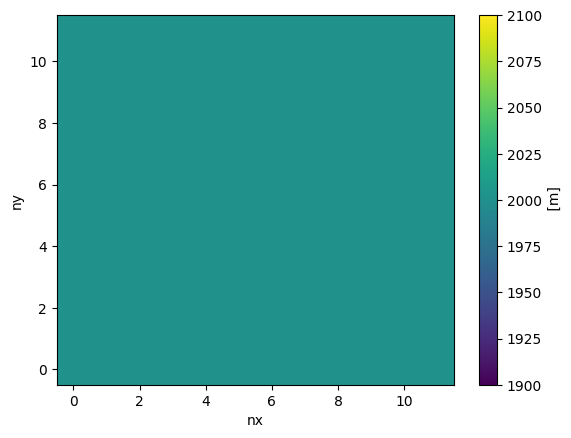

In [5]:
topo.depth.plot()

In [6]:
# Manually modify the bathymetry
%matplotlib ipympl
from mom6_bathy.topo_editor import TopoEditor
TopoEditor(topo)

TopoEditor(children=(VBox(children=(HTML(value='<h2>Topo Editor</h2>'), HTML(value='<hr><h3>Display</h3>'), To…

## 4. Create vertical grid

In [7]:
# Create a vertical grid
vgrid = VGrid.hyperbolic(
  nk    = 20,             # number of layers 
  depth = topo.max_depth, # Do NOT modify this argument 
  ratio = 10.0, # ratio of top to bottom layer thicknesses (=1.0 for uniform layers)
)
print('layer thicknesses:', vgrid.dz)

layer thicknesses: [ 18.48683013  18.77174174  19.32093315  20.37452048  22.37742844
  26.11992047  32.89271117  44.46845283  62.44562824  86.59356412
 113.40643588 137.55437176 155.53154717 167.10728883 173.88007953
 177.62257156 179.62547952 180.67906685 181.22825826 181.51316987]


## 5. Save the grid, bathymetry, and mesh files

In [8]:
# Do NOT modify this cell!

# MOM6 supergrid file.
grid.write_supergrid(f"/glade/derecho/scratch/manishrv/ergreg/ocnice/ocean_hgrid_112_8d9f40.nc")

# Save MOM6 topography file:
topo.write_topo(f"/glade/derecho/scratch/manishrv/ergreg/ocnice/ocean_topog_112_8d9f40.nc")

# Save MOM6 vertical grid file:
vgrid.write(f"/glade/derecho/scratch/manishrv/ergreg/ocnice/ocean_vgrid_112_8d9f40.nc")

# Save ESMF mesh file:
topo.write_esmf_mesh(f"/glade/derecho/scratch/manishrv/ergreg/ocnice/ESMF_mesh_112_8d9f40.nc")

If all cells have been executed successfully, you can return to visualCaseGen and click the 'Confirm completion' button to proceed to the next stage.